# Trial six: dt and speed

What changes when we change dt (the reaction time) and the speed, and what stays the same? If the turn limit and the noise are given **per decision**, the model only depends on the **step length** = speed × dt: no rule uses seconds. The story is in [chapter 6 of the README](../README.md#chapter-6-trial-six-dt-and-speed).

- **Part A:** check this shortcut exactly (same step length, turn and noise per decision or per second, and doubling every distance).
- **Part B:** sweep the step length from 0.025 to 1 BL for A0 (our model) and A4 (Puckett).
- **Part C:** two smaller step lengths, and Trial One on the same curve.

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the checks folder (it contains study_code/) and let Python import the shared study code.
CHECKS_FOLDER = Path.cwd()
while not (CHECKS_FOLDER / "study_code" / "study_tools.py").is_file():
    if CHECKS_FOLDER == CHECKS_FOLDER.parent:
        raise FileNotFoundError("study_code/study_tools.py was not found in this folder or any parent folder.")
    CHECKS_FOLDER = CHECKS_FOLDER.parent
sys.path.insert(0, str(CHECKS_FOLDER / "study_code"))

import study_tools
from study_tools import (
    A0_SETTINGS, PUCKETT_SETTINGS, A0_COLOR, PUCKETT_COLOR,
    build_model, change_settings, final_label_counts, record_trajectory, run_many, short_table, summarize,
)

# Where this trial keeps its saved results and its README figure.
DATA_FOLDER = CHECKS_FOLDER / "trial_six_dt_and_speed" / "data"
FIGURE_FOLDER = CHECKS_FOLDER / "trial_six_dt_and_speed" / "figures"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
from shiner_model import GoldenShinersModel

## Settings

In [2]:
SEEDS = list(range(10))
DT = PUCKETT_SETTINGS["dt"]                         # 0.125 s, our decision interval
REPULSION_RADIUS = PUCKETT_SETTINGS["repulsion_radius"]

# Part A1: pairs (speed BL/s, dt s) with the same step length.
SAME_STEP_LENGTH = {
    0.25: [(1.0, 0.25), (2.0, 0.125), (0.5, 0.5)],
    0.375: [(3.0, 0.125), (1.5, 0.25), (6.0, 0.0625)],
}
# Part A2: (1 BL/s, dt 0.25 s) against (2 BL/s, dt 0.125 s), both with step length 0.25 BL.
PAIR_A2 = [(1.0, 0.25), (2.0, 0.125)]
TURN_PER_DECISION = 1.75     # rad (Puckett et al. 2018, Table S1)
TURN_PER_SECOND = 14.0       # rad/s, the per-second version used in Trial Three (1.75 / 0.125)
NOISE = 0.01                 # rad
# Part A3: multiply every distance by this factor.
SCALE_FACTOR = 2

# Part B: step lengths (BL per decision); the speed is step length / dt.
STEP_LENGTHS = [0.025, 0.05, 0.1, 0.125, 0.2, 0.25, 0.375, 0.5, 0.625, 0.75, 1.0]
LIGHT_RANGE = (0.025, 0.625)   # 0.2 to 5 BL/s at dt = 0.125 s (Puckett et al. 2018)

# Part C: two extra, smaller step lengths, as small as in Trial Three.
EXTRA_STEP_LENGTHS = [0.00625, 0.0125]
# Trial One, notebook 04: polarization at 5 BL/s with three dt values (saved data of that trial).
TRIAL_ONE_CSV = CHECKS_FOLDER / "trial_one" / "data" / "04_timestep_case_summary.csv"
TRIAL_ONE_SPEED = 5.0

The configurations of parts B and C: A0 and A4 at every step length.

In [3]:
step_length_runs = []
for base in [A0_SETTINGS, PUCKETT_SETTINGS]:
    for step_length in STEP_LENGTHS:
        step_length_runs.append(change_settings(base, f"{base['base']}, ℓ={step_length:g}", {"speed": step_length / DT}))

extra_runs = []
for base in [A0_SETTINGS, PUCKETT_SETTINGS]:
    for step_length in EXTRA_STEP_LENGTHS:
        extra_runs.append(change_settings(base, f"{base['base']}, ℓ={step_length:g}", {"speed": step_length / DT}))

## Part A: the shortcut, checked exactly

Three small functions: a trajectory of the shared model, a trajectory of the study model, and the largest distance between the same fish in two runs.

In [4]:
def shared_model_trajectory(speed, dt, seed, n_decisions, max_turn_rate=None, angular_noise=0.0):
    """Positions after every decision in the shared model (shiner_model.py)."""
    model = GoldenShinersModel(speed=speed, dt=dt, seed=seed, max_turn_rate=max_turn_rate,
                               angular_noise=angular_noise, record_every=n_decisions + 1)
    return record_trajectory(model, n_decisions)


def study_model_trajectory(settings, speed, dt, seed, n_decisions):
    """Positions after every decision in the study model, with a given speed and dt."""
    changed = change_settings(settings, settings["label"], {"speed": speed, "dt": dt})
    return record_trajectory(build_model(changed, seed), n_decisions)


def largest_difference(trajectory_a, trajectory_b):
    """Largest distance (BL) between the same fish at the same decision in two runs."""
    distances = np.linalg.norm(trajectory_a - trajectory_b, axis=2)   # shape: (decisions, fish)
    return distances.max()

**A1.** Same step length, same trajectories? Every run swims 180 BL; A0 uses the shared model and A4 the study model.

In [5]:
rows = []
for step_length in SAME_STEP_LENGTH:
    pairs = SAME_STEP_LENGTH[step_length]
    n_decisions = round(study_tools.SWIM_DISTANCE / step_length)
    first_speed, first_dt = pairs[0]
    for seed in SEEDS:
        reference_a0 = shared_model_trajectory(first_speed, first_dt, seed, n_decisions)
        reference_a4 = study_model_trajectory(PUCKETT_SETTINGS, first_speed, first_dt, seed, n_decisions)
        for speed, dt in pairs[1:]:
            rows.append({
                "step length (BL)": step_length,
                "comparison": f"(v={first_speed:g}, dt={first_dt:g}) vs (v={speed:g}, dt={dt:g})",
                "A0 largest difference (BL)": largest_difference(reference_a0, shared_model_trajectory(speed, dt, seed, n_decisions)),
                "A4 largest difference (BL)": largest_difference(
                    reference_a4, study_model_trajectory(PUCKETT_SETTINGS, speed, dt, seed, n_decisions)),
            })
same_step = pd.DataFrame(rows)
assert same_step["A0 largest difference (BL)"].max() == 0.0
assert same_step["A4 largest difference (BL)"].max() == 0.0
same_step.groupby(["step length (BL)", "comparison"], sort=False).max()

A0 largest difference (BL)  A4 largest difference (BL)
step length (BL) comparison                                                                                 
0.250            (v=1, dt=0.25) vs (v=2, dt=0.125)                           0.0                         0.0
                 (v=1, dt=0.25) vs (v=0.5, dt=0.5)                           0.0                         0.0
0.375            (v=3, dt=0.125) vs (v=1.5, dt=0.25)                         0.0                         0.0
                 (v=3, dt=0.125) vs (v=6, dt=0.0625)                         0.0                         0.0

**A2.** Turn limit and noise per second (as in Trial Three, `shiner_model.py`) or per decision (as Puckett, the study model).

In [6]:
slow_speed, long_dt = PAIR_A2[0]
fast_speed, short_dt = PAIR_A2[1]
n_decisions = study_tools.number_of_decisions(slow_speed, long_dt)
turn_per_decision = change_settings(A0_SETTINGS, "turn per decision", {"turn_per_decision": TURN_PER_DECISION})
noise_per_decision = change_settings(A0_SETTINGS, "noise per decision", {"noise_per_decision": NOISE})

rows = []
for seed in SEEDS:
    rows.append({"version": "turn 14 rad/s (per second)", "seed": seed, "largest difference (BL)": largest_difference(
        shared_model_trajectory(slow_speed, long_dt, seed, n_decisions, max_turn_rate=TURN_PER_SECOND),
        shared_model_trajectory(fast_speed, short_dt, seed, n_decisions, max_turn_rate=TURN_PER_SECOND))})
    rows.append({"version": "turn 1.75 rad per decision", "seed": seed, "largest difference (BL)": largest_difference(
        study_model_trajectory(turn_per_decision, slow_speed, long_dt, seed, n_decisions),
        study_model_trajectory(turn_per_decision, fast_speed, short_dt, seed, n_decisions))})
    rows.append({"version": "noise 0.01 rad scaled with √dt (per second)", "seed": seed, "largest difference (BL)": largest_difference(
        shared_model_trajectory(slow_speed, long_dt, seed, n_decisions, angular_noise=NOISE),
        shared_model_trajectory(fast_speed, short_dt, seed, n_decisions, angular_noise=NOISE))})
    rows.append({"version": "noise 0.01 rad per decision", "seed": seed, "largest difference (BL)": largest_difference(
        study_model_trajectory(noise_per_decision, slow_speed, long_dt, seed, n_decisions),
        study_model_trajectory(noise_per_decision, fast_speed, short_dt, seed, n_decisions))})
turn_and_noise = pd.DataFrame(rows)

# Per decision: identical. Per second: different in every seed.
assert turn_and_noise[turn_and_noise["version"].str.contains("per decision")]["largest difference (BL)"].max() == 0.0
assert turn_and_noise[turn_and_noise["version"].str.contains("per second")]["largest difference (BL)"].min() > 0.0
turn_and_noise.groupby("version", sort=False)["largest difference (BL)"].agg(["min", "median", "max"])

,min,median,max
version,,,
turn 14 rad/s (per second),16.371,20.657,24.608
turn 1.75 rad per decision,0.000,0.000,0.000
noise 0.01 rad scaled with √dt (per second),11.684,21.300,24.680
noise 0.01 rad per decision,0.000,0.000,0.000


**A3.** Multiply the three radii, the arena and the step length by 2. If only proportions matter, the big school divided by 2 is exactly the small one.

In [7]:
def scaled(settings, factor):
    """The same configuration with every distance (radii, arena, step length) multiplied by factor."""
    changes = {}
    for key in ["repulsion_radius", "orientation_radius", "attraction_radius", "arena", "speed"]:
        changes[key] = settings[key] * factor
    return change_settings(settings, settings["label"] + f" x{factor:g}", changes)


rows = []
for settings in [A0_SETTINGS, PUCKETT_SETTINGS]:
    n_decisions = study_tools.number_of_decisions(settings["speed"], settings["dt"])
    for seed in SEEDS:
        small_run = record_trajectory(build_model(settings, seed), n_decisions)
        big_run = record_trajectory(build_model(scaled(settings, SCALE_FACTOR), seed), n_decisions)
        rows.append({"configuration": settings["label"],
                     "largest difference (BL)": largest_difference(big_run / SCALE_FACTOR, small_run)})
scaling = pd.DataFrame(rows)
assert scaling["largest difference (BL)"].max() == 0.0
scaling.groupby("configuration").max()

,largest difference (BL)
configuration,
A0,0.0
A4,0.0


## Run or load (parts B and C)

220 + 40 simulations; each run swims 180 BL, so it has 180 / step length decisions.

In [8]:
step_results = run_many(step_length_runs, SEEDS, DATA_FOLDER / "part_b_step_length.csv")
extra_results = run_many(extra_runs, SEEDS, DATA_FOLDER / "part_c_small_step_lengths.csv")

Loaded saved results from part_b_step_length.csv (set study_tools.RERUN = True to simulate again).
Loaded saved results from part_c_small_step_lengths.csv (set study_tools.RERUN = True to simulate again).


## Results tables

Mean ± standard error over the 10 seeds.

In [9]:
step_summary = summarize(step_results, ["label", "base", "step_length"])
short_table(step_summary)

,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,"A0, ℓ=0.025",9/10,0.94 ± 0.05,0.08 ± 0.07,0.52 ± 0.00,0.90 ± 0.10,0.00 ± 0.00,0.45 ± 0.00
1,"A0, ℓ=0.05",10/10,0.99 ± 0.00,0.02 ± 0.00,0.54 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.41 ± 0.00
2,"A0, ℓ=0.1",10/10,0.97 ± 0.00,0.02 ± 0.00,0.56 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.33 ± 0.01
3,"A0, ℓ=0.125",10/10,0.95 ± 0.00,0.03 ± 0.00,0.57 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.00
4,"A0, ℓ=0.2",6/10,0.90 ± 0.01,0.04 ± 0.00,0.60 ± 0.00,1.00 ± 0.00,0.05 ± 0.01,0.15 ± 0.01
5,"A0, ℓ=0.25",0/10,0.85 ± 0.01,0.09 ± 0.03,0.61 ± 0.00,0.94 ± 0.06,0.12 ± 0.01,0.07 ± 0.01
6,"A0, ℓ=0.375",0/10,0.69 ± 0.01,0.07 ± 0.00,0.59 ± 0.00,1.00 ± 0.00,0.51 ± 0.02,0.02 ± 0.00
7,"A0, ℓ=0.5",0/10,0.53 ± 0.01,0.08 ± 0.00,0.56 ± 0.00,1.00 ± 0.00,0.70 ± 0.02,0.02 ± 0.00
8,"A0, ℓ=0.625",0/10,0.48 ± 0.01,0.08 ± 0.00,0.56 ± 0.00,1.00 ± 0.00,0.74 ± 0.01,0.03 ± 0.00
9,"A0, ℓ=0.75",0/10,0.46 ± 0.01,0.09 ± 0.00,0.57 ± 0.00,1.00 ± 0.00,0.76 ± 0.02,0.02 ± 0.00


In [10]:
final_label_counts(step_results)

label_final,polarized,milling,swarm,fragmented
label,,,,
"A0, ℓ=0.025",9,0,0,1
"A0, ℓ=0.05",10,0,0,0
"A0, ℓ=0.1",10,0,0,0
"A0, ℓ=0.125",10,0,0,0
"A0, ℓ=0.2",10,0,0,0
"A0, ℓ=0.25",9,0,0,1
"A0, ℓ=0.375",7,0,3,0
"A0, ℓ=0.5",0,0,10,0
"A0, ℓ=0.625",0,0,10,0


Part C: the two smaller step lengths.

In [11]:
extra_summary = summarize(extra_results, ["label", "base", "step_length"])
short_table(extra_summary)

,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,"A0, ℓ=0.00625",9/10,0.96 ± 0.04,0.10 ± 0.07,0.52 ± 0.01,0.90 ± 0.10,0.00 ± 0.00,0.49 ± 0.00
1,"A0, ℓ=0.0125",10/10,1.00 ± 0.00,0.03 ± 0.00,0.51 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.48 ± 0.00
2,"A4, ℓ=0.00625",9/10,0.99 ± 0.01,0.06 ± 0.01,0.55 ± 0.03,0.99 ± 0.01,0.00 ± 0.00,0.49 ± 0.00
3,"A4, ℓ=0.0125",5/10,0.89 ± 0.06,0.18 ± 0.08,0.55 ± 0.01,0.78 ± 0.10,0.00 ± 0.00,0.48 ± 0.00


Trial One at 5 BL/s with three dt values, read from its saved data. These runs are our A0 with step lengths 0.625, 0.3125 and 0.156 BL.

In [12]:
trial_one = pd.read_csv(TRIAL_ONE_CSV)
trial_one = trial_one[trial_one["Speed_BL_s"] == TRIAL_ONE_SPEED]
trial_one_points = trial_one.groupby("Dt_s")["LatePolarization"].mean().reset_index()
trial_one_points["step length (BL)"] = TRIAL_ONE_SPEED * trial_one_points["Dt_s"]
trial_one_points

,Dt_s,LatePolarization,step length (BL)
0,0.031,0.945,0.156
1,0.062,0.785,0.312
2,0.125,0.476,0.625


## Figures

**The README figure.** Everything against the step length. Dashed line: the repulsion radius (0.5 BL). Grey band: the step lengths that light will cause. Log scale on the x axis.

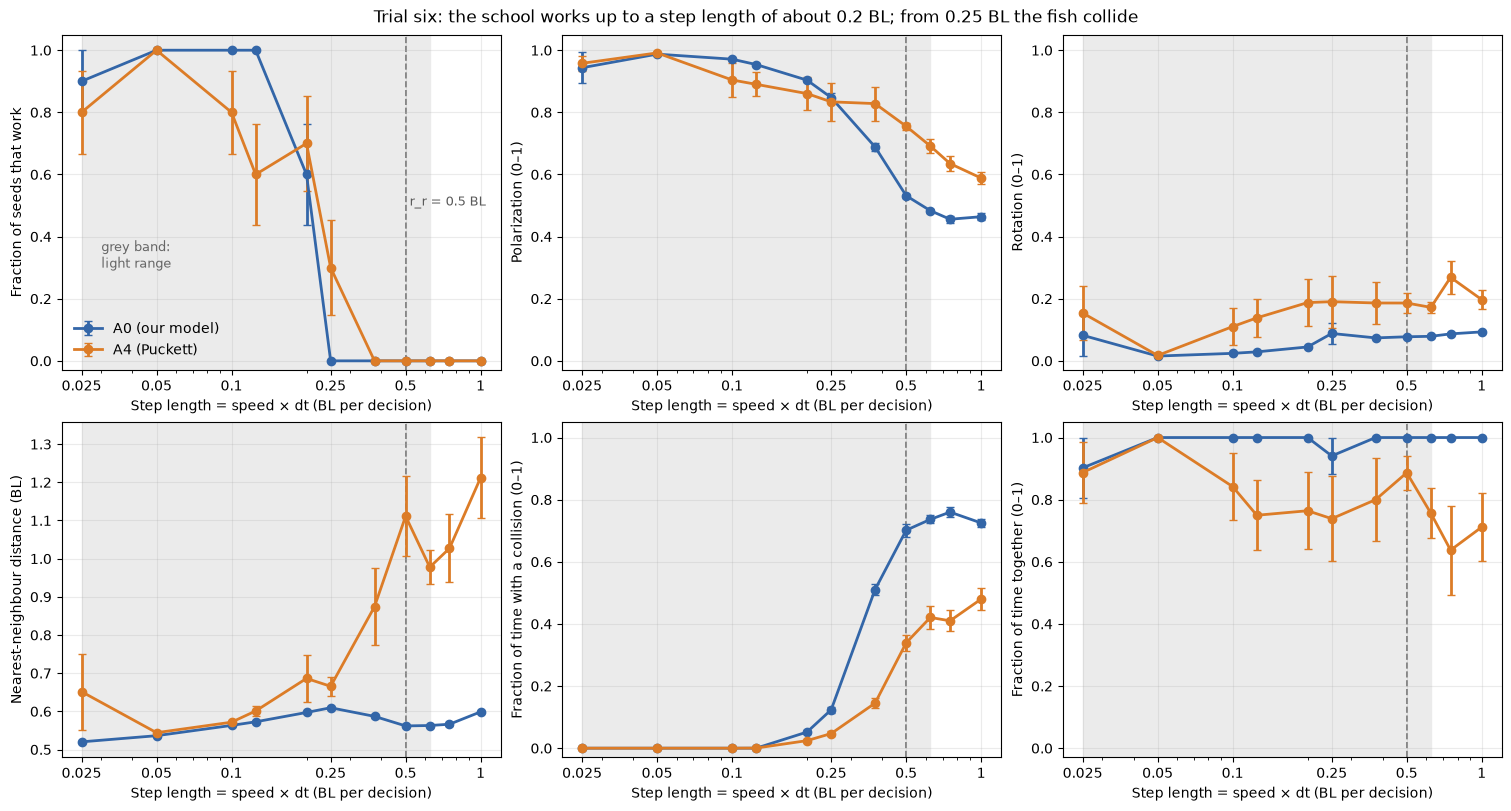

In [13]:
panels = [("works", "Fraction of seeds that work"), ("polarization", "Polarization (0–1)"),
          ("rotation", "Rotation (0–1)"), ("nnd", "Nearest-neighbour distance (BL)"),
          ("collision_fraction", "Fraction of time with a collision (0–1)"),
          ("together_fraction", "Fraction of time together (0–1)")]
BASE_COLORS = {"A0": A0_COLOR, "A4": PUCKETT_COLOR}
BASE_NAMES = {"A0": "A0 (our model)", "A4": "A4 (Puckett)"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for axis, (column, axis_label) in zip(axes.flat, panels):
    axis.axvspan(LIGHT_RANGE[0], LIGHT_RANGE[1], color="0.92", zorder=0)
    axis.axvline(REPULSION_RADIUS, color="0.45", linestyle="--", linewidth=1.2, zorder=1)
    for base in ["A0", "A4"]:
        rows = step_summary[step_summary["base"] == base]
        axis.errorbar(rows["step_length"], rows[column], yerr=rows[column + "_se"], color=BASE_COLORS[base],
                      marker="o", markersize=6, linewidth=2, capsize=3, label=BASE_NAMES[base], zorder=2)
    axis.set_xscale("log")
    axis.set_xticks([0.025, 0.05, 0.1, 0.25, 0.5, 1.0])
    axis.set_xticklabels(["0.025", "0.05", "0.1", "0.25", "0.5", "1"])
    axis.set_xlabel("Step length = speed × dt (BL per decision)")
    axis.set_ylabel(axis_label)
    axis.grid(alpha=0.25)
    if column != "nnd":
        axis.set_ylim(-0.03, 1.05)
axes[0, 0].legend(frameon=False, loc="lower left")
axes[0, 0].text(REPULSION_RADIUS, 0.5, " r_r = 0.5 BL", color="0.35", fontsize=9)
axes[0, 0].text(0.03, 0.3, "grey band:\nlight range", color="0.4", fontsize=9)
fig.suptitle("Trial six: the school works up to a step length of about 0.2 BL; from 0.25 BL the fish collide")
fig.savefig(FIGURE_FOLDER / "part_b_step_length.png", dpi=150)
plt.show()

Why collisions appear: two fish swimming towards each other come 2 × step length closer in one decision, so they can end at 0.5 − 2ℓ before they can react. Grey line: that rule; dots: the smallest distance measured in each run (mean of 10 seeds); dotted line: the collision threshold.

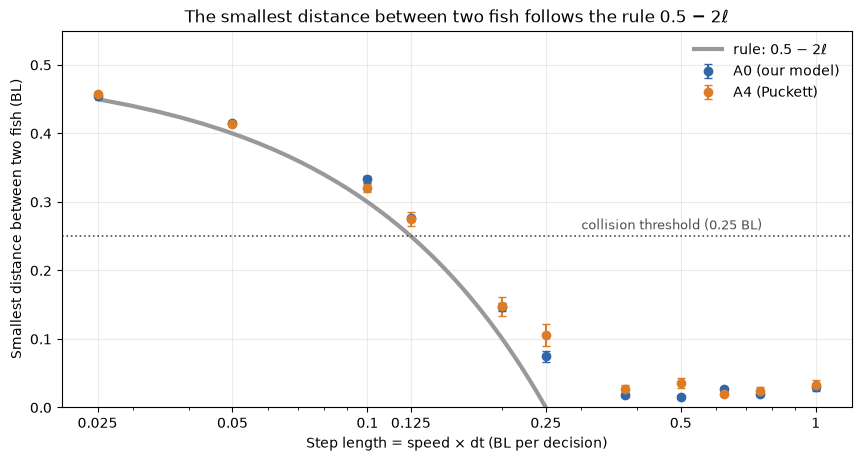

In [14]:
rule_steps = np.linspace(STEP_LENGTHS[0], REPULSION_RADIUS / 2, 50)   # up to where the rule reaches 0
fig, axis = plt.subplots(figsize=(8.5, 4.5), constrained_layout=True)
axis.plot(rule_steps, REPULSION_RADIUS - 2 * rule_steps, color="0.6", linewidth=3, label="rule: 0.5 − 2ℓ")
for base in ["A0", "A4"]:
    rows = step_summary[step_summary["base"] == base]
    axis.errorbar(rows["step_length"], rows["min_pair_distance"], yerr=rows["min_pair_distance_se"],
                  color=BASE_COLORS[base], marker="o", markersize=6, linestyle="none", capsize=3, label=BASE_NAMES[base])
axis.axhline(study_tools.COLLISION_DISTANCE, color="0.3", linestyle=":", linewidth=1.2)
axis.text(0.3, study_tools.COLLISION_DISTANCE + 0.01, "collision threshold (0.25 BL)", color="0.3", fontsize=9)
axis.set_xscale("log")
axis.set_xticks([0.025, 0.05, 0.1, 0.125, 0.25, 0.5, 1.0])
axis.set_xticklabels(["0.025", "0.05", "0.1", "0.125", "0.25", "0.5", "1"])
axis.set_xlabel("Step length = speed × dt (BL per decision)")
axis.set_ylabel("Smallest distance between two fish (BL)")
axis.set_ylim(0, 0.55)
axis.grid(alpha=0.25)
axis.legend(frameon=False, loc="upper right")
axis.set_title("The smallest distance between two fish follows the rule 0.5 − 2ℓ")
plt.show()

Trial One on the curve of A0 (black crosses).

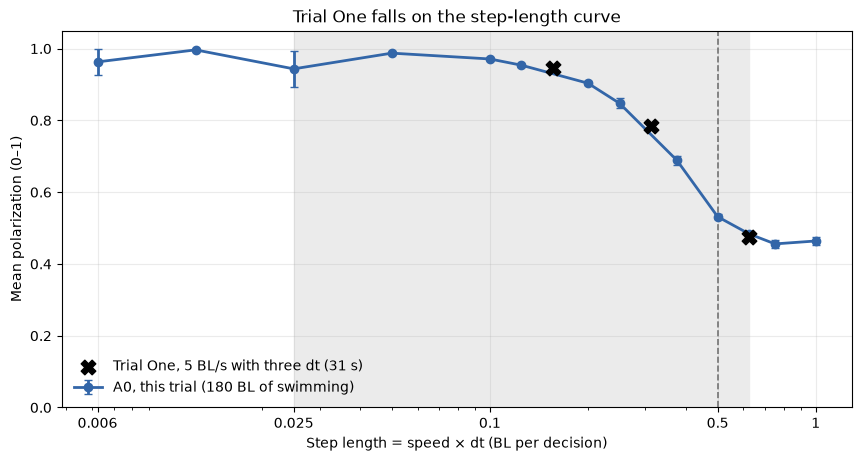

In [15]:
all_a0 = pd.concat([extra_summary[extra_summary["base"] == "A0"], step_summary[step_summary["base"] == "A0"]])
all_a0 = all_a0.sort_values("step_length")

fig, axis = plt.subplots(figsize=(8.5, 4.5), constrained_layout=True)
axis.axvspan(LIGHT_RANGE[0], LIGHT_RANGE[1], color="0.92", zorder=0)
axis.axvline(REPULSION_RADIUS, color="0.45", linestyle="--", linewidth=1.2)
axis.errorbar(all_a0["step_length"], all_a0["polarization"], yerr=all_a0["polarization_se"], color=A0_COLOR,
              marker="o", markersize=6, linewidth=2, capsize=3, label="A0, this trial (180 BL of swimming)")
axis.scatter(trial_one_points["step length (BL)"], trial_one_points["LatePolarization"], marker="X", s=110,
             color="black", zorder=3, label="Trial One, 5 BL/s with three dt (31 s)")
axis.set_xscale("log")
axis.set_xticks([0.00625, 0.025, 0.1, 0.5, 1.0])
axis.set_xticklabels(["0.006", "0.025", "0.1", "0.5", "1"])
axis.set_xlabel("Step length = speed × dt (BL per decision)")
axis.set_ylabel("Mean polarization (0–1)")
axis.set_ylim(0, 1.05)
axis.grid(alpha=0.25)
axis.legend(frameon=False, loc="lower left")
axis.set_title("Trial One falls on the step-length curve")
plt.show()

## Conclusion

- **Only the step length matters** when the turn limit and the noise are per decision: the same step length gives exactly the same trajectories (difference 0), and doubling every distance gives the same school, twice as big. Per-second turn limits or noise break this.
- **A0 works in 9 or 10 of 10 seeds up to a step length of 0.125 BL, in 6 at 0.2 and in none from 0.25.** The smallest distance follows 0.5 − 2ℓ, which crosses the collision threshold at 0.125 BL.
- **Trial One falls on the curve:** its "dt problem" was this same step-length effect.